# LeukoGuard — Member 1, Part E: RQ3, LR error analysis and odds ratios

**RQ3:** *Do derived features such as the neutrophil-to-lymphocyte ratio (NLR) improve the results compared to raw counts alone?*

## Design
| Factor | Levels |
|---|---|
| Feature set | **Full**: all 71 raw CBC features · **Core**: the 24 standard routine-CBC values (5-part differential, red cells, platelets) that any lab reports |
| Comparison | **raw** vs **raw + derived** (NLR, PLR, MLR, SII, dNLR) |
| Preprocessing | **log pipeline** (main, as in Part D) · **no-log** (sensitivity analysis: tests whether ratios help when the model cannot build them from log-counts, see Part C3.3) |
| Model | Identical for every configuration: the Part D model (L2, C from D, class weights). Only the feature set changes |

**Statistical comparison**
1. **Development, 5 × 5 repeated stratified CV** (25 paired folds; raw and raw+derived see identical folds). Metrics: ROC-AUC, PR-AUC, specificity at 90% recall.
   Test: **Nadeau–Bengio corrected resampled t-test** (corrects the ordinary t-test for overlapping training sets), plus Wilcoxon signed-rank as a non-parametric check, with Holm correction across the 6 primary tests.
2. **Unseen hospitals D–G**: models fitted on all development data. **Paired DeLong test** for ROC-AUC, **paired bootstrap** (1,000×) for PR-AUC, and **McNemar** for the decisions at each model's own 90%-recall threshold.

In [1]:
import sys, time, warnings, joblib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.base import clone
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold
from sklearn.metrics import roc_auc_score, average_precision_score

ROOT = Path("..").resolve() if Path.cwd().name == "notebooks" else Path(".").resolve()
sys.path.insert(0, str(ROOT / "src"))
from leuko_common import FEATURES, CORE_FEATURES, DERIVED, LOG_FEATURES, KEY_FEATURES, SEED
from lr_pipeline import (LRScreen, oof_predict, threshold_for_recall, spec_at_recall, metrics_at,
                         corrected_resampled_ttest, delong_test, bootstrap_diff, mcnemar)

FIG_DIR = ROOT / "reports" / "figures"; TAB_DIR = ROOT / "reports" / "tables"; PRED_DIR = ROOT / "reports" / "predictions"
warnings.filterwarnings("ignore")
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 150, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
C_HC, C_LK, C_RAW, C_DER = "#2a78d6", "#eb6834", "#2a78d6", "#eb6834"
def savefig(name): plt.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight")

D = joblib.load(ROOT / "models" / "lr_final.joblib")
HP = dict(C=D["model"].C, l1_ratio=D["model"].l1_ratio, imbalance=D["model"].imbalance)
TARGET_RECALL = D["target_recall"]
print("Model settings carried over from Part D:", HP, "| target recall:", TARGET_RECALL)

fe = pd.read_csv(ROOT / "data" / "features" / "leukoalert_features.csv.gz")
dev = fe[fe.cohort == "development"].reset_index(drop=True); y = dev["y"].astype(int)
ext = fe[fe.cohort == "external_validation"].reset_index(drop=True)
print(f"Development {len(dev):,} | external hospitals D–G {len(ext):,} ({100*ext.y.mean():.1f}% leukemia)")

CONFIGS = {  # name: (feature list, use_log)
    "Full raw":           (FEATURES, True),
    "Full raw+derived":   (FEATURES + DERIVED, True),
    "Core raw":           (CORE_FEATURES, True),
    "Core raw+derived":   (CORE_FEATURES + DERIVED, True),
    "Full raw (no-log)":         (FEATURES, False),
    "Full raw+derived (no-log)": (FEATURES + DERIVED, False),
    "Core raw (no-log)":         (CORE_FEATURES, False),
    "Core raw+derived (no-log)": (CORE_FEATURES + DERIVED, False),
}
def model_for(name):
    feats, use_log = CONFIGS[name]
    return LRScreen(features=feats, log_features=LOG_FEATURES, use_log=use_log, seed=SEED, **HP)

Model settings carried over from Part D: {'C': 0.01, 'l1_ratio': 0.0, 'imbalance': 'balanced'} | target recall: 0.9
Development 26,922 | external hospitals D–G 149,623 (3.9% leukemia)


## E1. Repeated cross-validation on the development set (5 folds × 5 repeats)

In [2]:
rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=SEED)
rfolds = list(rskf.split(dev, y))
n_test = len(rfolds[0][1]); n_train = len(rfolds[0][0])
rows = []
t0 = time.time()
for name in CONFIGS:
    base = model_for(name)
    for i, (tr, te) in enumerate(rfolds):
        m = clone(base).fit(dev.iloc[tr], y.iloc[tr]); p = m.predict_proba(dev.iloc[te])[:, 1]
        rows.append({"config": name, "fold": i, "ROC_AUC": roc_auc_score(y.iloc[te], p),
                     "PR_AUC": average_precision_score(y.iloc[te], p), "spec@recall90": spec_at_recall(y.iloc[te], p, TARGET_RECALL)})
cvres = pd.DataFrame(rows)
cvres.to_csv(TAB_DIR / "E1_repeated_cv_per_fold.csv", index=False)
print(f"{len(CONFIGS)} configurations × {len(rfolds)} folds fitted in {time.time()-t0:.0f}s")
cv_mean = cvres.groupby("config", sort=False)[["ROC_AUC", "PR_AUC", "spec@recall90"]].agg(["mean", "std"])
cv_mean.round(4)

8 configurations × 25 folds fitted in 182s


ROC_AUC          PR_AUC         spec@recall90        
                             mean     std    mean     std          mean     std
config                                                                         
Full raw                   0.9679  0.0024  0.9296  0.0059        0.9314  0.0060
Full raw+derived           0.9685  0.0025  0.9308  0.0061        0.9338  0.0064
Core raw                   0.9460  0.0033  0.8901  0.0078        0.8723  0.0108
Core raw+derived           0.9508  0.0032  0.8990  0.0075        0.8854  0.0105
Full raw (no-log)          0.9636  0.0024  0.9242  0.0057        0.9239  0.0056
Full raw+derived (no-log)  0.9658  0.0025  0.9288  0.0059        0.9283  0.0059
Core raw (no-log)          0.9295  0.0032  0.8607  0.0078        0.8278  0.0122
Core raw+derived (no-log)  0.9436  0.0033  0.8878  0.0082        0.8651  0.0113

In [3]:
METRICS = ["ROC_AUC", "PR_AUC", "spec@recall90"]
tests = []
for fs in ["Full", "Core"]:
    for suffix, family in [("", "primary (log pipeline)"), (" (no-log)", "sensitivity (no-log)")]:
        a_name, b_name = f"{fs} raw{suffix}", f"{fs} raw+derived{suffix}"
        A = cvres[cvres.config == a_name].set_index("fold"); B = cvres[cvres.config == b_name].set_index("fold")
        for met in METRICS:
            d = (B[met] - A[met]).values
            mean, t, p = corrected_resampled_ttest(d, n_train, n_test)
            se = np.sqrt((1 / len(d) + n_test / n_train) * d.var(ddof=1))
            tcrit = stats.t.ppf(0.975, len(d) - 1)
            w_p = stats.wilcoxon(d).pvalue if np.any(d != 0) else 1.0
            tests.append({"family": family, "feature set": fs, "metric": met, "raw": A[met].mean(), "raw+derived": B[met].mean(),
                          "difference": mean, "95% CI low": mean - tcrit * se, "95% CI high": mean + tcrit * se,
                          "p (corrected t)": p, "p (Wilcoxon)": w_p, "derived better in folds": f"{(d > 0).sum()}/{len(d)}"})
tt = pd.DataFrame(tests)
for fam in tt.family.unique():   # Holm correction within each family of 6 tests
    m_ = tt.family == fam
    pv = tt.loc[m_, "p (corrected t)"].values; order = np.argsort(pv); k = len(pv)
    adj = np.minimum(1, np.maximum.accumulate((k - np.arange(k)) * pv[order]))
    out = np.empty(k); out[order] = adj
    tt.loc[m_, "p Holm"] = out
tt.to_csv(TAB_DIR / "E1_rq3_cv_tests.csv", index=False)
fmt = tt.copy()
for c in ["raw", "raw+derived", "difference", "95% CI low", "95% CI high"]: fmt[c] = fmt[c].map("{:.4f}".format)
for c in ["p (corrected t)", "p (Wilcoxon)", "p Holm"]: fmt[c] = fmt[c].map("{:.3g}".format)
fmt

,family,feature set,metric,raw,raw+derived,difference,95% CI low,95% CI high,p (corrected t),p (Wilcoxon),derived better in folds,p Holm
0,primary (log pipeline),Full,ROC_AUC,0.9679,0.9685,0.0006,0.0003,0.0009,0.00018,5.96e-08,25/25,0.000541
1,primary (log pipeline),Full,PR_AUC,0.9296,0.9308,0.0011,0.0005,0.0018,0.00187,2.98e-07,23/25,0.00374
2,primary (log pipeline),Full,spec@recall90,0.9314,0.9338,0.0024,0.0002,0.0045,0.0333,6.69e-05,22/25,0.0333
3,sensitivity (no-log),Full,ROC_AUC,0.9636,0.9658,0.0022,0.0016,0.0029,2.01e-07,5.96e-08,25/25,6.02e-07
4,sensitivity (no-log),Full,PR_AUC,0.9242,0.9288,0.0046,0.0033,0.0060,3.27e-07,5.96e-08,25/25,6.55e-07
5,sensitivity (no-log),Full,spec@recall90,0.9239,0.9283,0.0044,0.0013,0.0076,0.00785,2.34e-05,23/25,0.00785
6,primary (log pipeline),Core,ROC_AUC,0.9460,0.9508,0.0048,0.0040,0.0056,2.09e-11,5.96e-08,25/25,1.26e-10
7,primary (log pipeline),Core,PR_AUC,0.8901,0.8990,0.0089,0.0073,0.0106,4.74e-11,5.96e-08,25/25,2.37e-10
8,primary (log pipeline),Core,spec@recall90,0.8723,0.8854,0.0131,0.0076,0.0186,5.51e-05,5.96e-08,25/25,0.00022
9,sensitivity (no-log),Core,ROC_AUC,0.9295,0.9436,0.0142,0.0121,0.0162,2.94e-13,5.96e-08,25/25,1.47e-12


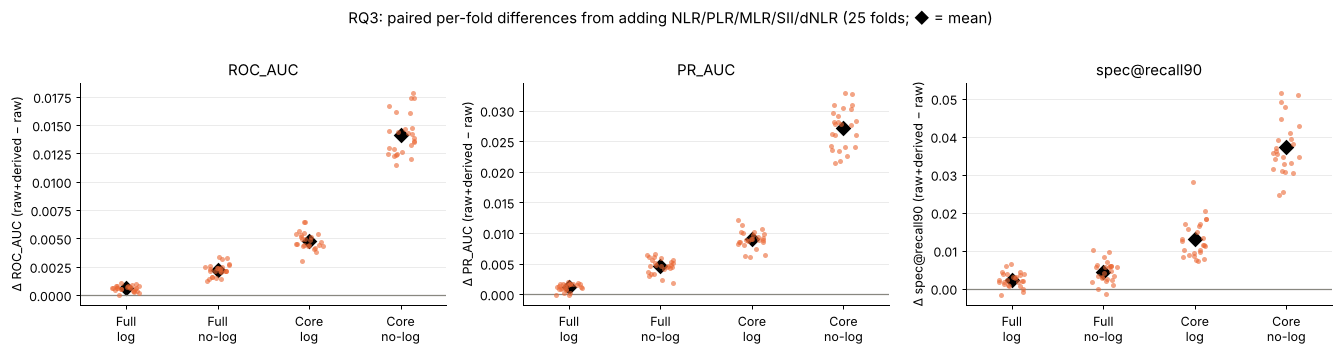

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, met in zip(axes, METRICS):
    rowsp = []
    for fs in ["Full", "Core"]:
        for suffix, lab in [("", "log"), (" (no-log)", "no-log")]:
            A = cvres[cvres.config == f"{fs} raw{suffix}"].set_index("fold")[met]
            B = cvres[cvres.config == f"{fs} raw+derived{suffix}"].set_index("fold")[met]
            for v in (B - A).values: rowsp.append({"setting": f"{fs}\n{lab}", "diff": v})
    dp = pd.DataFrame(rowsp)
    sns.stripplot(data=dp, x="setting", y="diff", ax=ax, color=C_DER, alpha=.6, size=4, jitter=.15)
    sns.pointplot(data=dp, x="setting", y="diff", ax=ax, color="black", errorbar=None, markers="D", linestyles="none")
    ax.axhline(0, color="#888780", lw=1); ax.set_xlabel(""); ax.set_ylabel(f"Δ {met} (raw+derived − raw)")
    ax.set_title(met)
fig.suptitle("RQ3: paired per-fold differences from adding NLR/PLR/MLR/SII/dNLR (25 folds; ◆ = mean)", y=1.02)
plt.tight_layout(); savefig("E1_rq3_paired_differences"); plt.show()

## E2. Unseen hospitals D–G
Each configuration (log pipeline) is fitted on all development data. Its threshold is set on its own OOF predictions (Part D folds) at 90% recall, then evaluated on the four external hospitals.

In [5]:
std_folds = list(StratifiedKFold(5, shuffle=True, random_state=SEED).split(dev, y))
ext_pred, thr = {}, {}
for name in ["Full raw", "Full raw+derived", "Core raw", "Core raw+derived"]:
    m = model_for(name)
    thr[name] = threshold_for_recall(y, oof_predict(m, dev, y, std_folds), TARGET_RECALL)
    ext_pred[name] = clone(m).fit(dev, y).predict_proba(ext)[:, 1]

ap = lambda yy, pp: average_precision_score(yy, pp)
ext_rows = []
for fs in ["Full", "Core"]:
    a, b = f"{fs} raw", f"{fs} raw+derived"
    for site in ["D", "E", "F", "G", "pooled"]:
        msk = np.ones(len(ext), bool) if site == "pooled" else (ext.site == site).values
        yy = ext.y.values[msk]; pa, pb = ext_pred[a][msk], ext_pred[b][msk]
        auc_a, auc_b, z, p_dl = delong_test(yy, pa, pb)
        ma, mb = metrics_at(yy, pa, thr[a]), metrics_at(yy, pb, thr[b])
        r = {"feature set": fs, "site": site, "n": int(msk.sum()), "ROC_AUC raw": auc_a, "ROC_AUC +der": auc_b, "ΔROC_AUC": auc_b - auc_a, "p DeLong": p_dl,
             "PR_AUC raw": ap(yy, pa), "PR_AUC +der": ap(yy, pb), "recall raw": ma["recall"], "recall +der": mb["recall"],
             "spec raw": ma["specificity"], "spec +der": mb["specificity"]}
        if site == "pooled":
            dlt, lo, hi, p_bs = bootstrap_diff(yy, pa, pb, ap, n_boot=1000, seed=SEED)
            b_, c_, p_mc = mcnemar(yy, (pa >= thr[a]).astype(int), (pb >= thr[b]).astype(int))
            r.update({"ΔPR_AUC [95% CI]": f"{dlt:+.4f} [{lo:+.4f}, {hi:+.4f}]", "p bootstrap": p_bs,
                      "McNemar (only raw right / only +der right)": f"{b_} / {c_}", "p McNemar": p_mc})
        ext_rows.append(r)
ext_tab = pd.DataFrame(ext_rows)
ext_tab.to_csv(TAB_DIR / "E2_rq3_external_hospitals.csv", index=False)
show = ext_tab.copy()
for c in ["p DeLong", "p bootstrap", "p McNemar"]: show[c] = show[c].map(lambda v: "" if pd.isna(v) else ("< 1e-16" if v < 1e-16 else f"{v:.2g}"))
show.round(4).fillna("")

,feature set,site,n,ROC_AUC raw,ROC_AUC +der,ΔROC_AUC,p DeLong,PR_AUC raw,PR_AUC +der,recall raw,recall +der,spec raw,spec +der,ΔPR_AUC [95% CI],p bootstrap,McNemar (only raw right / only +der right),p McNemar
0,Full,D,30156,0.9545,0.9548,0.0004,0.12,0.5256,0.5283,0.9184,0.9162,0.8621,0.8652,,,,
1,Full,E,94318,0.9651,0.9657,0.0006,0.00016,0.5212,0.5220,0.8778,0.8755,0.9330,0.9338,,,,
2,Full,F,20179,0.9637,0.9635,-0.0002,0.5,0.5631,0.5545,0.8746,0.8655,0.9312,0.9337,,,,
3,Full,G,4970,0.9125,0.9137,0.0012,0.001,0.6382,0.6450,0.8530,0.8454,0.8447,0.8494,,,,
4,Full,pooled,149623,0.9595,0.9599,0.0003,0.0049,0.5292,0.5289,0.8826,0.8783,0.9160,0.9177,"-0.0004 [-0.0023, +0.0016]",0.7,350 / 563,1.8e-12
5,Core,D,30156,0.9385,0.9416,0.0031,2.9e-07,0.5059,0.5159,0.8958,0.8927,0.8213,0.8367,,,,
6,Core,E,94318,0.9481,0.9520,0.0039,3.2e-15,0.4686,0.4904,0.8782,0.8653,0.8965,0.9106,,,,
7,Core,F,20179,0.9356,0.9413,0.0057,1.4e-05,0.4905,0.5001,0.8574,0.8392,0.8794,0.8937,,,,
8,Core,G,4970,0.8914,0.8967,0.0053,9.4e-09,0.5908,0.6209,0.9070,0.8919,0.7387,0.7607,,,,
9,Core,pooled,149623,0.9442,0.9478,0.0036,< 1e-16,0.4905,0.5070,0.8833,0.8714,0.8747,0.8893,"+0.0165 [+0.0124, +0.0203]",0.001,483 / 2516,< 1e-16


## E3. RQ3 answer

In [6]:
def get(fam, fs, met, col):
    return tt[(tt.family == fam) & (tt["feature set"] == fs) & (tt.metric == met)][col].iloc[0]
for fam in ["primary (log pipeline)", "sensitivity (no-log)"]:
    print(f"--- {fam} ---")
    for fs in ["Full", "Core"]:
        print(f"{fs:4s}: ΔROC-AUC {get(fam, fs, 'ROC_AUC', 'difference'):+.4f} (Holm p={get(fam, fs, 'ROC_AUC', 'p Holm'):.3g}), "
              f"ΔPR-AUC {get(fam, fs, 'PR_AUC', 'difference'):+.4f} (p={get(fam, fs, 'PR_AUC', 'p Holm'):.3g}), "
              f"Δspec@90%recall {get(fam, fs, 'spec@recall90', 'difference'):+.4f} (p={get(fam, fs, 'spec@recall90', 'p Holm'):.3g})")
pe = ext_tab[ext_tab.site == "pooled"]
for _, r in pe.iterrows():
    print(f"External pooled, {r['feature set']}: ΔROC-AUC {r['ΔROC_AUC']:+.4f} (DeLong p={r['p DeLong']:.3g}), ΔPR-AUC {r['ΔPR_AUC [95% CI]']} (p={r['p bootstrap']:.3g}), "
          f"recall {r['recall raw']:.3f}→{r['recall +der']:.3f}, spec {r['spec raw']:.3f}→{r['spec +der']:.3f}")

--- primary (log pipeline) ---
Full: ΔROC-AUC +0.0006 (Holm p=0.000541), ΔPR-AUC +0.0011 (p=0.00374), Δspec@90%recall +0.0024 (p=0.0333)
Core: ΔROC-AUC +0.0048 (Holm p=1.26e-10), ΔPR-AUC +0.0089 (p=2.37e-10), Δspec@90%recall +0.0131 (p=0.00022)
--- sensitivity (no-log) ---
Full: ΔROC-AUC +0.0022 (Holm p=6.02e-07), ΔPR-AUC +0.0046 (p=6.55e-07), Δspec@90%recall +0.0044 (p=0.00785)
Core: ΔROC-AUC +0.0142 (Holm p=1.47e-12), ΔPR-AUC +0.0271 (p=5.78e-13), Δspec@90%recall +0.0372 (p=6.08e-09)
External pooled, Full: ΔROC-AUC +0.0003 (DeLong p=0.00485), ΔPR-AUC -0.0004 [-0.0023, +0.0016] (p=0.7), recall 0.883→0.878, spec 0.916→0.918
External pooled, Core: ΔROC-AUC +0.0036 (DeLong p=8.92e-26), ΔPR-AUC +0.0165 [+0.0124, +0.0203] (p=0.001), recall 0.883→0.871, spec 0.875→0.889


**Answer to RQ3.** Yes, but **only when the model does not already have the information the ratios summarise.**

| Setting | Gain from adding NLR, PLR, MLR, SII, dNLR | Verdict |
|---|---|---|
| **Full 71-feature panel, log pipeline** (our main LR) | CV: ROC-AUC **+0.0006**, PR-AUC +0.001, specificity@90% recall +0.2 pp. Statistically significant (better in 22–25 of 25 folds, Holm p < 0.05) but **tiny**. Unseen hospitals: ROC-AUC +0.0003, PR-AUC −0.0004 (95% CI −0.002 to +0.002, p = 0.70) | **No practical benefit** |
| **Routine 24-value CBC, log pipeline** | CV: ROC-AUC **+0.005**, PR-AUC **+0.009**, specificity@90% recall **+1.3 pp** (all p < 0.001). Unseen hospitals: ROC-AUC +0.004 (DeLong p < 10⁻²⁵), PR-AUC **+0.017** [0.012, 0.020], better at every hospital | **Small but real and consistent benefit** |
| **Routine CBC, no log transform** | CV: ROC-AUC **+0.014**, PR-AUC **+0.027**, specificity@90% recall **+3.7 pp** | **Clear benefit** |

**Why.** As Part C predicted, a ratio is non-linear in its counts. An LR on log-counts can already build log(NEUT#/LYMPH#) as a weighted difference, and the full 71-parameter panel contains near-copies of the ratios (LYMPH%, NEUT%) plus research channels that carry the same information.
The less the model already knows (fewer features, no log transform), the more the ratios add.

**Practical meaning.** For labs with a **standard 5-part-differential analyser** (common in Pakistani hospitals, and the setting in the proposal's limitations), adding NLR-type ratios is worthwhile.
With the full Sysmex research panel it adds nothing measurable. One caveat: at the frozen thresholds the Core + derived model **trades a little recall for specificity** at unseen hospitals (recall 0.883 → 0.871, specificity 0.875 → 0.889).
The ranking (AUC) improved, so a re-tuned threshold would recover the recall.

## E4. Error analysis of the Part D Logistic Regression (unseen hospitals D–G)
Uses the saved predictions of the final Part D model (Full raw, threshold frozen from CV).

In [7]:
pe_ = pd.read_csv(PRED_DIR / "lr_raw71_eval_predictions.csv.gz")
pe_ = pe_[pe_.cohort == "external_validation"].merge(ext[["sample_id"] + FEATURES + DERIVED], on="sample_id")
THR = D["threshold"]
pe_["pred"] = (pe_.p >= THR).astype(int)
pe_["outcome"] = np.select([(pe_.y == 1) & (pe_.pred == 1), (pe_.y == 1) & (pe_.pred == 0), (pe_.y == 0) & (pe_.pred == 1)], ["TP", "FN", "FP"], "TN")
print(pe_.outcome.value_counts().to_dict())
prof = pe_.groupby("outcome")[["WBC", "NEUT#", "LYMPH#", "LYMPH%", "MONO#", "HGB", "MCV", "RDW-CV", "PLT", "IG#", "NRBC#", "NLR"]].median().loc[["TP", "FN", "FP", "TN"]]
prof["diff missing %"] = pe_.groupby("outcome")["NEUT#"].apply(lambda s: 100 * s.isna().mean())
prof["median score"] = pe_.groupby("outcome")["p"].median()
prof.to_csv(TAB_DIR / "E4_error_profiles.csv")
prof.round(2)

{'TN': 131763, 'FP': 12076, 'TP': 5105, 'FN': 679}


,WBC,NEUT#,LYMPH#,LYMPH%,MONO#,HGB,MCV,RDW-CV,PLT,IG#,NRBC#,NLR,diff missing %,median score
outcome,,,,,,,,,,,,,,
TP,1.57,0.73,0.56,39.55,0.10,76.0,93.0,15.5,36.0,0.02,0.0,0.98,7.70,0.97
FN,4.97,3.41,0.83,19.00,0.27,102.0,93.7,15.1,169.0,0.03,0.0,3.62,0.29,0.28
FP,3.79,2.05,0.75,22.80,0.33,87.0,93.8,16.7,105.5,0.04,0.0,2.67,14.98,0.80
TN,6.75,4.30,1.50,23.30,0.42,124.0,92.1,13.2,225.0,0.03,0.0,2.83,0.09,0.05


**How "normal" are the missed leukemias?** For each leukemia record we count how many of the three main lines are abnormal (anaemia HGB < 120 g/L, thrombocytopenia PLT < 150, WBC outside 4–11 ×10⁹/L), using standard adult reference limits.

In [8]:
lk = pe_[pe_.y == 1].copy()
lk["anaemia"] = lk.HGB < 120; lk["thrombocytopenia"] = lk.PLT < 150; lk["WBC abnormal"] = ~lk.WBC.between(4, 11)
lk["n abnormal lines"] = lk[["anaemia", "thrombocytopenia", "WBC abnormal"]].sum(axis=1)
lk["WBC band"] = pd.cut(lk.WBC, [-1, 4, 11, 30, 1e4], labels=["<4 (low)", "4–11 (normal)", "11–30 (high)", ">30 (very high)"])
t1 = lk.groupby("n abnormal lines").agg(leukemia_records=("y", "size"), recall=("pred", "mean"))
t1["share of all misses %"] = 100 * lk[lk.pred == 0].groupby("n abnormal lines").size() / (lk.pred == 0).sum()
t2 = lk.groupby("WBC band", observed=True).agg(leukemia_records=("y", "size"), recall=("pred", "mean"))
t3 = lk.groupby("site").agg(leukemia_records=("y", "size"), recall=("pred", "mean"))
display(t1.round(3)); display(t2.round(3)); display(t3.round(3))
pd.concat({"by n abnormal lines": t1, "by WBC band": t2, "by site": t3}).to_csv(TAB_DIR / "E4_recall_breakdown.csv")

,leukemia_records,recall,share of all misses %
n abnormal lines,,,
0,69,0.159,8.542
1,496,0.500,36.524
2,1291,0.798,38.439
3,3928,0.971,16.495


,leukemia_records,recall
WBC band,,
<4 (low),4166,0.942
4–11 (normal),1025,0.655
11–30 (high),325,0.775
>30 (very high),267,0.963


,leukemia_records,recall
site,,
D,1324,0.918
E,2546,0.878
F,989,0.875
G,925,0.853


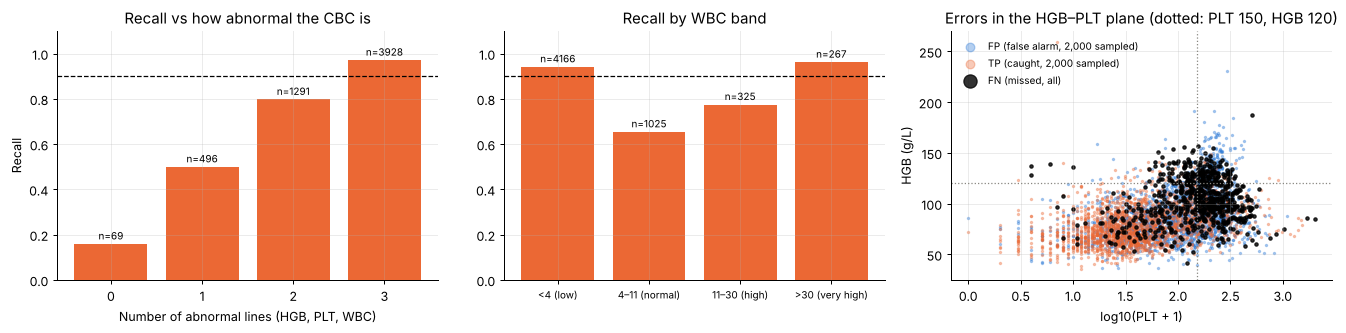

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
axes[0].bar(t1.index.astype(str), t1.recall, color=C_LK); axes[0].set_xlabel("Number of abnormal lines (HGB, PLT, WBC)")
axes[0].set_ylabel("Recall"); axes[0].set_title("Recall vs how abnormal the CBC is")
for i, (r, n) in enumerate(zip(t1.recall, t1.leukemia_records)): axes[0].text(i, r + .02, f"n={n}", ha="center", fontsize=8)
axes[1].bar(t2.index.astype(str), t2.recall, color=C_LK); axes[1].set_title("Recall by WBC band"); axes[1].tick_params(axis="x", labelsize=8)
for i, (r, n) in enumerate(zip(t2.recall, t2.leukemia_records)): axes[1].text(i, r + .02, f"n={n}", ha="center", fontsize=8)
for ax in axes[:2]: ax.set_ylim(0, 1.1); ax.axhline(TARGET_RECALL, color="black", ls="--", lw=1)
# draw order: false alarms (sampled) → caught (sampled) → ALL missed cases on top
for k, c, lab, n, sz, al in [("FP", C_HC, "FP (false alarm, 2,000 sampled)", 2000, 3, .35), ("TP", C_LK, "TP (caught, 2,000 sampled)", 2000, 3, .35),
                             ("FN", "black", "FN (missed, all)", None, 7, .8)]:
    s_ = pe_[pe_.outcome == k]
    if n: s_ = s_.sample(min(n, len(s_)), random_state=SEED)
    axes[2].scatter(np.log10(s_.PLT + 1), s_.HGB, s=sz, alpha=al, color=c, label=lab)
axes[2].axvline(np.log10(151), color="#888780", ls=":", lw=1); axes[2].axhline(120, color="#888780", ls=":", lw=1)
axes[2].set_xlabel("log10(PLT + 1)"); axes[2].set_ylabel("HGB (g/L)"); axes[2].legend(frameon=False, markerscale=4, fontsize=8)
axes[2].set_title("Errors in the HGB–PLT plane (dotted: PLT 150, HGB 120)")
plt.tight_layout(); savefig("E4_error_analysis"); plt.show()

In [10]:
# Do the derived features rescue the raw model's misses?
fn_raw = (ext.y == 1) & (ext_pred["Full raw"] < thr["Full raw"])
fn_der = (ext.y == 1) & (ext_pred["Full raw+derived"] < thr["Full raw+derived"])
print(f"Missed by raw model: {fn_raw.sum()} | missed by raw+derived: {fn_der.sum()} | missed by both: {(fn_raw & fn_der).sum()}")
print(f"Rescued by adding ratios: {(fn_raw & ~fn_der).sum()} | newly missed after adding ratios: {(~fn_raw & fn_der).sum()}")

Missed by raw model: 679 | missed by raw+derived: 704 | missed by both: 651
Rescued by adding ratios: 28 | newly missed after adding ratios: 53


**Reading (E4): what the LR gets wrong.**
* **Missed leukemias (FN) look almost normal.** Their median WBC is 5.0, HGB 102 g/L and PLT 169, against WBC 1.6, HGB 76 and PLT 36 in the caught cases.
  Recall is **97% when all three lines are abnormal but only 16% when none are**, and 45% of all misses have at most one abnormal line.
  These are likely early, treated/remission, or chronic leukemias (e.g. CLL, where a mild lymphocytosis may be the only sign). A routine-CBC screen cannot be expected to catch them.
* **The linear model under-uses high WBC.** Recall is 94% for low WBC and 96% for very high WBC (> 30), but only **78% for WBC 11–30** and 66% for normal WBC.
  LR gives WBC a single direction (lower = riskier, because most leukemia records here are leukopenic), so a moderate leukocytosis pushes the score the wrong way. This is a structural limit of a linear model. **Tree models (Members 2/3) should do better on this subgroup**, which makes it a good comparison point.
* **False alarms (FP) are sick non-leukemia patients.** Their median HGB is 87, PLT 106 and RDW 16.7, and 15% have no differential.
  That pattern fits other causes of cytopenia (chemotherapy, other marrow disease, sepsis), so these are clinically understandable flags, not random noise.
* **The derived ratios do not fix the misses.** Adding them rescues 28 missed cases and loses 53 others at the frozen thresholds (Full panel).

## E5. Coefficients and odds ratios
### E5.1 Main model (Part D, 71 features + missing indicators)
Coefficients are on the **standardised transformed scale**: OR = e^β is the change in odds of leukemia per **1 SD** increase of the (log-)feature, holding all others fixed.
Because of the strong collinearity (EDA A9), single coefficients of this model should be read with care. **Stability** across the 5 CV fits is shown (same sign in all folds = more trustworthy).

In [11]:
main = D["model"]
coef = main.coefficients()
fold_coefs = pd.DataFrame({k: clone(main).fit(dev.iloc[tr], y.iloc[tr]).coefficients() for k, (tr, _) in enumerate(std_folds)})
st = pd.DataFrame({"coef": coef, "OR per SD": np.exp(coef), "fold SD": fold_coefs.std(axis=1),
                   "same sign in all folds": (np.sign(fold_coefs).nunique(axis=1) == 1) & (fold_coefs.abs().min(axis=1) > 0)})
st = st.reindex(st.coef.abs().sort_values(ascending=False).index)
st.to_csv(TAB_DIR / "E5_main_model_coefficients.csv")
print(f"Coefficients with a consistent sign across folds: {st['same sign in all folds'].sum()} of {len(st)}")
st.head(20).round(3)

Coefficients with a consistent sign across folds: 126 of 138


,coef,OR per SD,fold SD,same sign in all folds
MO-WY,-0.577,0.561,0.020,True
NE-FSC,-0.536,0.585,0.020,True
HGB Defect,0.500,1.649,0.007,True
NE-WX,0.498,1.646,0.006,True
MicroR,0.483,1.621,0.021,True
NEUT#&,-0.469,0.626,0.018,True
HFLC%,-0.442,0.643,0.018,True
NEUT#,-0.430,0.650,0.019,True
EO%,-0.421,0.656,0.018,True
LY-X,0.410,1.507,0.028,True


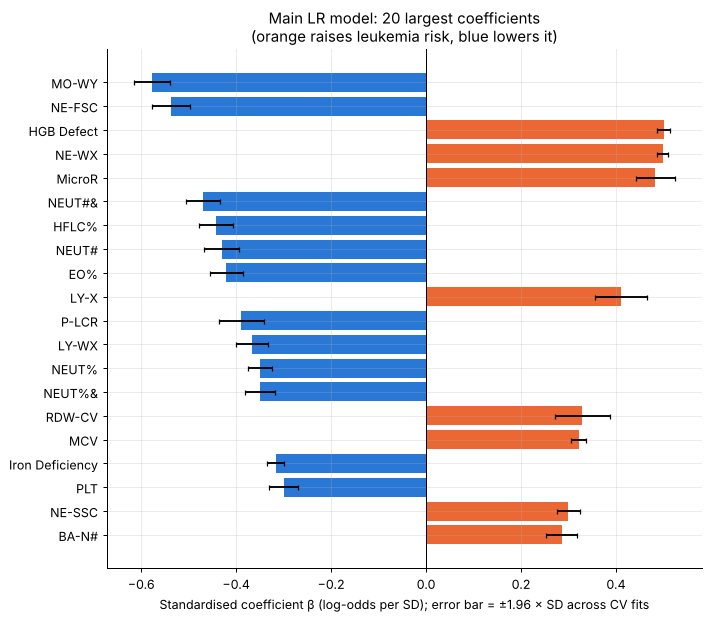

In [12]:
top = st.head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(top.index, top.coef, xerr=1.96 * top["fold SD"], color=[C_LK if c > 0 else C_HC for c in top.coef], capsize=2)
ax.axvline(0, color="black", lw=.8)
ax.set_xlabel("Standardised coefficient β (log-odds per SD); error bar = ±1.96 × SD across CV fits")
ax.set_title("Main LR model: 20 largest coefficients\n(orange raises leukemia risk, blue lowers it)")
plt.tight_layout(); savefig("E5_main_model_coefficients"); plt.show()

### E5.2 A readable model for interpretation (de-duplicated routine CBC)
To interpret odds ratios cleanly, we fit a small LR on routine values with **one representative per redundant group** (VIF < 5).
95% CIs come from **500 bootstrap resamples** of the development set. The model is almost unpenalised (C = 100) so the ORs are not shrunk.

In [13]:
# NEUT% is left out on purpose: NEUT% + LYMPH% + MONO% + EO% + BASO% = 100%, so keeping all three
# percentages gives VIF > 60 and a NEUT% odds ratio with the wrong sign.
READABLE = ["WBC", "LYMPH%", "MONO%", "HGB", "MCV", "RDW-CV", "PLT", "MPV"]
rd = LRScreen(features=READABLE, log_features=LOG_FEATURES, C=100, l1_ratio=0.0, imbalance="balanced", seed=SEED)
Z = rd.fit(dev, y).transform(dev)[:, :len(READABLE)]
def vif_of(Z):
    """Variance inflation factor of each column: 1 / (1 - R²) regressing it on all the others."""
    out = []
    for j in range(Z.shape[1]):
        A = np.c_[np.ones(len(Z)), np.delete(Z, j, 1)]
        resid = Z[:, j] - A @ np.linalg.lstsq(A, Z[:, j], rcond=None)[0]
        out.append(1 / (resid.var() / Z[:, j].var()))
    return out
vif = vif_of(Z)
oof_rd = oof_predict(rd, dev, y, std_folds)
print(f"Readable model CV ROC-AUC {roc_auc_score(y, oof_rd):.3f}, PR-AUC {average_precision_score(y, oof_rd):.3f} "
      f"(main 71-feature model: ROC-AUC {roc_auc_score(y, pd.read_csv(PRED_DIR / 'lr_raw71_oof_development.csv').p_oof):.3f})")
rng = np.random.default_rng(SEED); boots = []
for b in range(500):
    idx = rng.integers(0, len(dev), len(dev))
    boots.append(clone(rd).fit(dev.iloc[idx], y.iloc[idx]).coefficients())
B = pd.DataFrame(boots)
c0 = rd.coefficients()
ors = pd.DataFrame({"β": c0, "OR per SD": np.exp(c0), "OR 95% CI low": np.exp(B.quantile(.025)), "OR 95% CI high": np.exp(B.quantile(.975))})
ors["VIF"] = pd.Series(vif, index=READABLE)
ors["transform"] = ["log1p" if f in LOG_FEATURES else "linear" for f in ors.index.str.replace("MISSING_", "")]
ors.loc[ors.index.str.startswith("MISSING_"), "transform"] = "indicator"
ors["direction"] = np.where(ors["OR 95% CI low"] > 1, "↑ risk", np.where(ors["OR 95% CI high"] < 1, "↓ risk", "n.s."))
ors.to_csv(TAB_DIR / "E5_readable_model_odds_ratios.csv")
ors.round(3)

Readable model CV ROC-AUC 0.931, PR-AUC 0.862 (main 71-feature model: ROC-AUC 0.968)


,β,OR per SD,OR 95% CI low,OR 95% CI high,VIF,transform,direction
WBC,-0.680,0.507,0.476,0.539,1.920,log1p,↓ risk
LYMPH%,0.318,1.375,1.298,1.452,1.393,linear,↑ risk
MONO%,0.488,1.629,1.559,1.710,1.100,linear,↑ risk
HGB,-0.694,0.500,0.473,0.527,1.802,linear,↓ risk
MCV,0.335,1.398,1.340,1.459,1.028,linear,↑ risk
RDW-CV,0.576,1.779,1.710,1.857,1.253,linear,↑ risk
PLT,-1.274,0.280,0.261,0.301,2.070,log1p,↓ risk
MPV,-0.346,0.708,0.677,0.738,1.104,linear,↓ risk
MISSING_WBC,-0.037,0.963,0.928,0.965,NaN,indicator,↓ risk
MISSING_LYMPH%,0.050,1.051,1.023,1.086,NaN,indicator,↑ risk


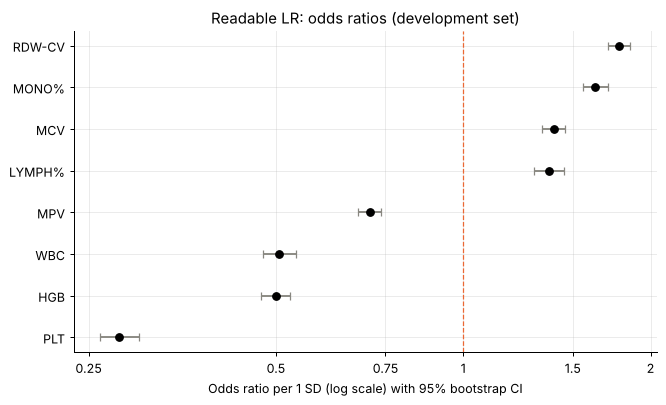

In [14]:
o = ors[~ors.index.str.startswith("MISSING_")].sort_values("OR per SD")   # indicators listed in the table
fig, ax = plt.subplots(figsize=(7.5, 4.6))
ax.errorbar(o["OR per SD"], range(len(o)), xerr=[o["OR per SD"] - o["OR 95% CI low"], o["OR 95% CI high"] - o["OR per SD"]],
            fmt="o", color="black", ecolor="#888780", capsize=3)
ax.axvline(1, color=C_LK, lw=1, ls="--"); ax.set_xscale("log")
ax.set_xticks([0.25, 0.5, 0.75, 1, 1.5, 2]); ax.set_xticklabels(["0.25", "0.5", "0.75", "1", "1.5", "2"]); ax.minorticks_off()
ax.set_yticks(range(len(o))); ax.set_yticklabels(o.index)
ax.set_xlabel("Odds ratio per 1 SD (log scale) with 95% bootstrap CI"); ax.set_title("Readable LR: odds ratios (development set)")
plt.tight_layout(); savefig("E5_readable_odds_ratios"); plt.show()

In [15]:
# Where does NLR land when it is added to the readable model?
rd2 = LRScreen(features=READABLE + ["NLR"], log_features=LOG_FEATURES, C=100, l1_ratio=0.0, imbalance="balanced", seed=SEED).fit(dev, y)
c2 = rd2.coefficients()
oof_rd2 = oof_predict(rd2, dev, y, std_folds)
print(f"Readable + NLR: CV ROC-AUC {roc_auc_score(y, oof_rd2):.4f} (without NLR {roc_auc_score(y, oof_rd):.4f})")
Z2 = rd2.transform(dev)[:, :len(READABLE) + 1]
print("VIF with NLR added:", dict(zip(READABLE + ["NLR"], np.round(vif_of(Z2), 2))))
print("Coefficients (log-odds per SD) without / with NLR:")
pd.DataFrame({"without NLR": c0.reindex(READABLE + ["NLR"]), "with NLR": c2.reindex(READABLE + ["NLR"])}).round(3)

Readable + NLR: CV ROC-AUC 0.9381 (without NLR 0.9308)
VIF with NLR added: {'WBC': np.float64(2.12), 'LYMPH%': np.float64(4.94), 'MONO%': np.float64(1.54), 'HGB': np.float64(1.86), 'MCV': np.float64(1.03), 'RDW-CV': np.float64(1.25), 'PLT': np.float64(2.23), 'MPV': np.float64(1.11), 'NLR': np.float64(5.15)}
Coefficients (log-odds per SD) without / with NLR:


,without NLR,with NLR
WBC,-0.680,-0.897
LYMPH%,0.318,1.497
MONO%,0.488,0.832
HGB,-0.694,-0.617
MCV,0.335,0.338
RDW-CV,0.576,0.569
PLT,-1.274,-1.142
MPV,-0.346,-0.378
NLR,NaN,1.229


**Reading (E5): coefficients and odds ratios.**
* **Main model.** The largest standardised coefficients belong to analyser channels and flags: cell-population parameters (MO-WY, NE-FSC, NE-WX, LY-X), the HGB-Defect and Iron-Deficiency Q-flags, and MicroR. Neutrophil counts (NEUT#, NEUT#&), PLT, RDW-CV and MCV come next.
  126 of 138 coefficients keep the same sign in all 5 CV fits, so the large ones are stable. Because near-duplicate channels share the signal, an individual OR in this model is **not** a clean "effect of that feature"; use the readable model for interpretation.
* **Readable model** (8 routine values, VIF ≤ 2.1, CV ROC-AUC 0.931 vs 0.968 for the full model). Per 1 SD, adjusted for the others:
  **PLT is the strongest marker** (OR ≈ 0.28: each SD lower in log-PLT roughly triples to quadruples the odds). Next come **HGB** (OR ≈ 0.50, lower = riskier), **WBC** (OR ≈ 0.50, low WBC = riskier in this cohort), **RDW-CV** (OR ≈ 1.78), **MONO%** and **LYMPH%** (higher = riskier) and **MCV** (OR ≈ 1.40, macrocytosis); MPV is lower in leukemia.
  These directions match the clinical picture of marrow infiltration: thrombocytopenia, anaemia, cytopenia or abnormal white cells, anisocytosis, relative lymphocytosis/monocytosis. They also match the literature list for RQ2.
* **Adding NLR to the readable model** raises CV ROC-AUC (see above), but NLR's own coefficient becomes **positive** even though NLR is *lower* in leukemia univariately, and the LYMPH% coefficient grows.
  This is a classic **suppression effect** between a ratio and its components (VIF ≈ 5). When a ratio sits next to its components, its odds ratio means "NLR given the same LYMPH%", not "high NLR is a leukemia sign". This needs stating whenever derived-feature ORs are reported.